<a href="https://colab.research.google.com/github/LiliAlania/drone-multi-object-detection/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Setup
Configure paths and analysis parameters. Data is read from Colab's local `/content/data` when available.

In [15]:
from pathlib import Path
import subprocess, shutil

SEED = 42
MOUNT_DRIVE = False
REPO_URL = "https://github.com/LiliAlania/drone-multi-object-detection.git"
REPO_DIR = Path("/content/drone-multi-object-detection")
DATA_ROOT = Path("/content/data")
TEST_CSV = DATA_ROOT / "test_images.csv"
TRAIN_COCO = DATA_ROOT / "train" / "annotations_coco.json"
VAL_COCO = DATA_ROOT / "val" / "annotations_coco.json"
RESULTS_DIR = REPO_DIR / "results" / "eda"
ANCHORS_PATH = REPO_DIR / "results" / "anchors.json"
FIGURES_DIR = REPO_DIR / "figures" / "eda"
SPLITS_DIR = REPO_DIR / "splits"
IMGSZ_CANDIDATES = [640, 960, 1280, 1536]
ANCHOR_IMGSZ = 960
ANCHOR_K_VALUES = [9, 12]
SUBSAMPLE_STEP = 5
FOLD_COUNT = 5
CONSISTENCY_SAMPLE_FRAMES = 20
TEMPORAL_LAGS = [1, 2, 3, 5, 10, 15, 20, 30]
VISUAL_FRAME_COUNT = 6
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
!rm -rf /content/drone-multi-object-detection

In [3]:
def git(*args):
    r = subprocess.run(["git", *args], capture_output=True, text=True)
    print(r.stdout, r.stderr)
    r.check_returncode()

if REPO_DIR.exists() and not (REPO_DIR / ".git").exists():
    shutil.rmtree(REPO_DIR)  # leftover folder that isn't a repo

if not REPO_DIR.exists():
    git("clone", REPO_URL, str(REPO_DIR))
else:
    git("-C", str(REPO_DIR), "pull")

assert (REPO_DIR / "src" / "data_utils.py").exists(), "src/data_utils.py not in repo — push it first"

 Cloning into '/content/drone-multi-object-detection'...



In [4]:
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
assert (REPO_DIR / "src" / "data_utils.py").exists(), "src/data_utils.py not in repo — push it first"

In [5]:
import importlib.util
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB and MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
if not (REPO_DIR / "src" / "data_utils.py").exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
from src import data_utils as du

In [6]:
import os
from google.colab import userdata
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!pip install -q kaggle
!kaggle competitions list -s "ucu-ai-2026"

ref                                                                                   deadline             category   reward  teamCount  userHasEntered  
------------------------------------------------------------------------------------  -------------------  ---------  ------  ---------  --------------  
https://www.kaggle.com/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026  2026-11-09 23:55:00  Community   Kudos         23            True  


In [7]:
if DATA_ROOT.exists():
    print(f"Using existing dataset directory: {DATA_ROOT}")
else:
    downloader = REPO_DIR / "src" / "get_data.py"
    subprocess.run([sys.executable, str(downloader), "--output-dir", str(DATA_ROOT)], check=True)
required_files = [TRAIN_COCO, VAL_COCO]
missing_files = [path for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Expected dataset files not found: {missing_files}")
print(f"Train: {TRAIN_COCO.exists()} | val: {VAL_COCO.exists()} | test CSV: {TEST_CSV.exists()}")

Train: True | val: True | test CSV: True


# 1. Load annotations and verify YOLO conversion
Load split metadata, separate target objects from crowd/ignored regions, and compare stored YOLO boxes with normalized COCO boxes.

In [8]:
imgs, anns = du.load_coco(TRAIN_COCO, "train")
print("duplicate image ids:", imgs["id"].duplicated().sum())

img = imgs[imgs["file_name"].str.contains("uav0000323_01173_v")
           & imgs["file_name"].str.contains("0000308")]
ign = anns[(anns["image_id"] == img["id"].iloc[0]) & (anns["iscrowd"] == 1)]
print("ignored in COCO:", len(ign), "| unique boxes:", ign["bbox"].map(tuple).nunique())

duplicate image ids: 0
ignored in COCO: 64 | unique boxes: 8


In [12]:
import importlib
importlib.reload(du)

<module 'src.data_utils' from '/content/drone-multi-object-detection/src/data_utils.py'>

In [11]:
import json
from collections import Counter

coco = json.load(open(TRAIN_COCO))
img = next(i for i in coco["images"]
           if i["file_name"].endswith("uav0000323_01173_v/0000308.jpg"))
print(img)

crowd = [a for a in coco["annotations"]
         if a["image_id"] == img["id"] and a.get("iscrowd", 0) == 1]
print("iscrowd у COCO:", len(crowd))
print("унікальних bbox:", len({tuple(round(v, 1) for v in a["bbox"]) for a in crowd}))
print("orig_category_id:", Counter(a.get("orig_category_id") for a in crowd))

# скільки зображень з таким самим file_name / id
print("зображень з цим id:", sum(i["id"] == img["id"] for i in coco["images"]))

{'id': 20956, 'file_name': 'images/uav0000323_01173_v/0000308.jpg', 'width': 1904, 'height': 1071, 'video_id': 47, 'video': 'uav0000323_01173_v', 'frame_id': 308}
iscrowd у COCO: 64
унікальних bbox: 8
orig_category_id: Counter({0: 56, 11: 8})
зображень з цим id: 1


In [23]:
train_images_raw, train_annotations_raw = du.load_coco(TRAIN_COCO, "train")
val_images_raw, val_annotations_raw = du.load_coco(VAL_COCO, "val")
train_target_raw, train_ignored_raw = du.split_annotations(train_annotations_raw)
val_target_raw, val_ignored_raw = du.split_annotations(val_annotations_raw)
consistency = {
    "train": du.check_yolo_consistency(TRAIN_COCO, DATA_ROOT / "train", "train", CONSISTENCY_SAMPLE_FRAMES, SEED),
    "val": du.check_yolo_consistency(VAL_COCO, DATA_ROOT / "val", "val", CONSISTENCY_SAMPLE_FRAMES, SEED),
}
print("YOLO/COCO consistency:", consistency)
images, annotations = du.namespace_image_ids(
    [train_images_raw, val_images_raw], [train_annotations_raw, val_annotations_raw]
)
targets, ignored = du.split_annotations(annotations)
targets = du.add_box_dimensions(targets, target_only=False)  # ← додати: class_name, box_w, box_h, area, sqrt_area...
train_images = images.loc[images["split"].eq("train")].copy()
val_images = images.loc[images["split"].eq("val")].copy()
train_targets = targets.loc[targets["split"].eq("train")].copy()
val_targets = targets.loc[targets["split"].eq("val")].copy()

YOLO/COCO consistency: {'train': {'sampled_frames': 20, 'target_boxes_compared': 813, 'ignored_regions_compared': 84, 'ignored_duplicates_removed': 446901}, 'val': {'sampled_frames': 20, 'target_boxes_compared': 1085, 'ignored_regions_compared': 26, 'ignored_duplicates_removed': 27965}}


**Observations:** TODO

# 2. Dataset overview
Compare clip/frame counts and resolution frequencies for train, validation, and test using annotation metadata and the test CSV.

,split,clips,frames,resolutions
0,test,48,3811,6
1,train,56,24201,6
2,val,7,2846,5


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,48.0,79.4,34.5,35.0,48.8,73.5,108.2,148.0
train,56.0,432.2,275.1,58.0,223.5,383.5,550.0,1424.0
val,7.0,406.6,268.3,184.0,254.0,349.0,413.5,978.0


,split,resolution,frames
0,test,1344x756,441
1,test,1360x764,1474
2,test,1904x1072,305
3,test,1920x1080,991
4,test,680x382,321
5,test,960x540,279
6,train,1344x756,5645
7,train,1360x765,962
8,train,1904x1071,12895
9,train,1920x1080,721


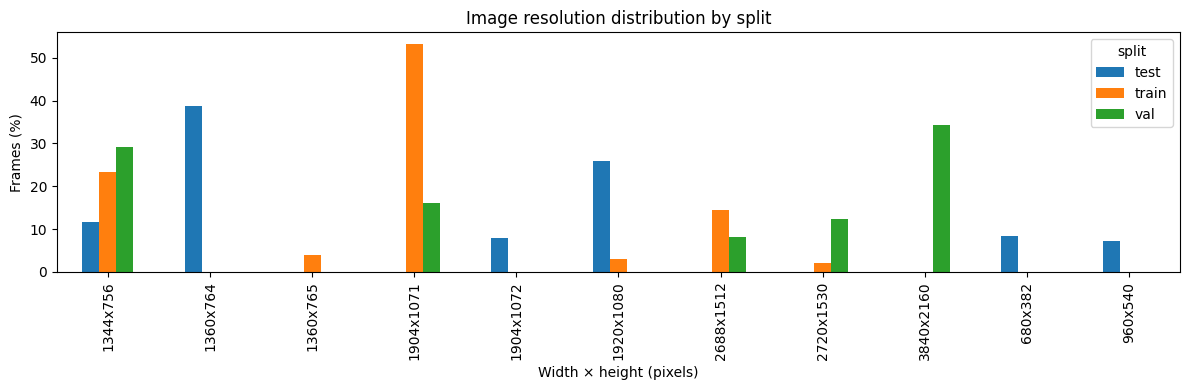

In [16]:
test_csv_path = TEST_CSV if TEST_CSV.exists() else None
overview, frames_per_clip, resolution_counts = du.dataset_overview(
    {"train": train_images, "val": val_images}, test_csv_path
)
display(overview)
display(frames_per_clip.groupby("split")["frames"].describe().round(1))
display(resolution_counts.head(20))
resolution_pct = resolution_counts.assign(
    percent=resolution_counts["frames"]
    / resolution_counts.groupby("split")["frames"].transform("sum") * 100
)
resolution_pivot = resolution_pct.pivot(index="resolution", columns="split", values="percent").fillna(0)
ax = resolution_pivot.plot(kind="bar", figsize=(12, 4))
ax.set(title="Image resolution distribution by split", xlabel="Width × height (pixels)", ylabel="Frames (%)")
plt = __import__("matplotlib.pyplot", fromlist=["pyplot"])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "resolution_distribution.png", dpi=140)
plt.show()

**Observations:** TODO

# 3. Class distribution
Inspect target counts and per-clip class shares; examine original VisDrone category IDs and their target/ignored status.

split,train,val
class_name,,
bicycle,40255,6022
bus,9653,264
car,505301,31821
motor,102819,12025
person,328701,50312
tricycle,41349,5487
truck,30498,1359
van,46940,6842


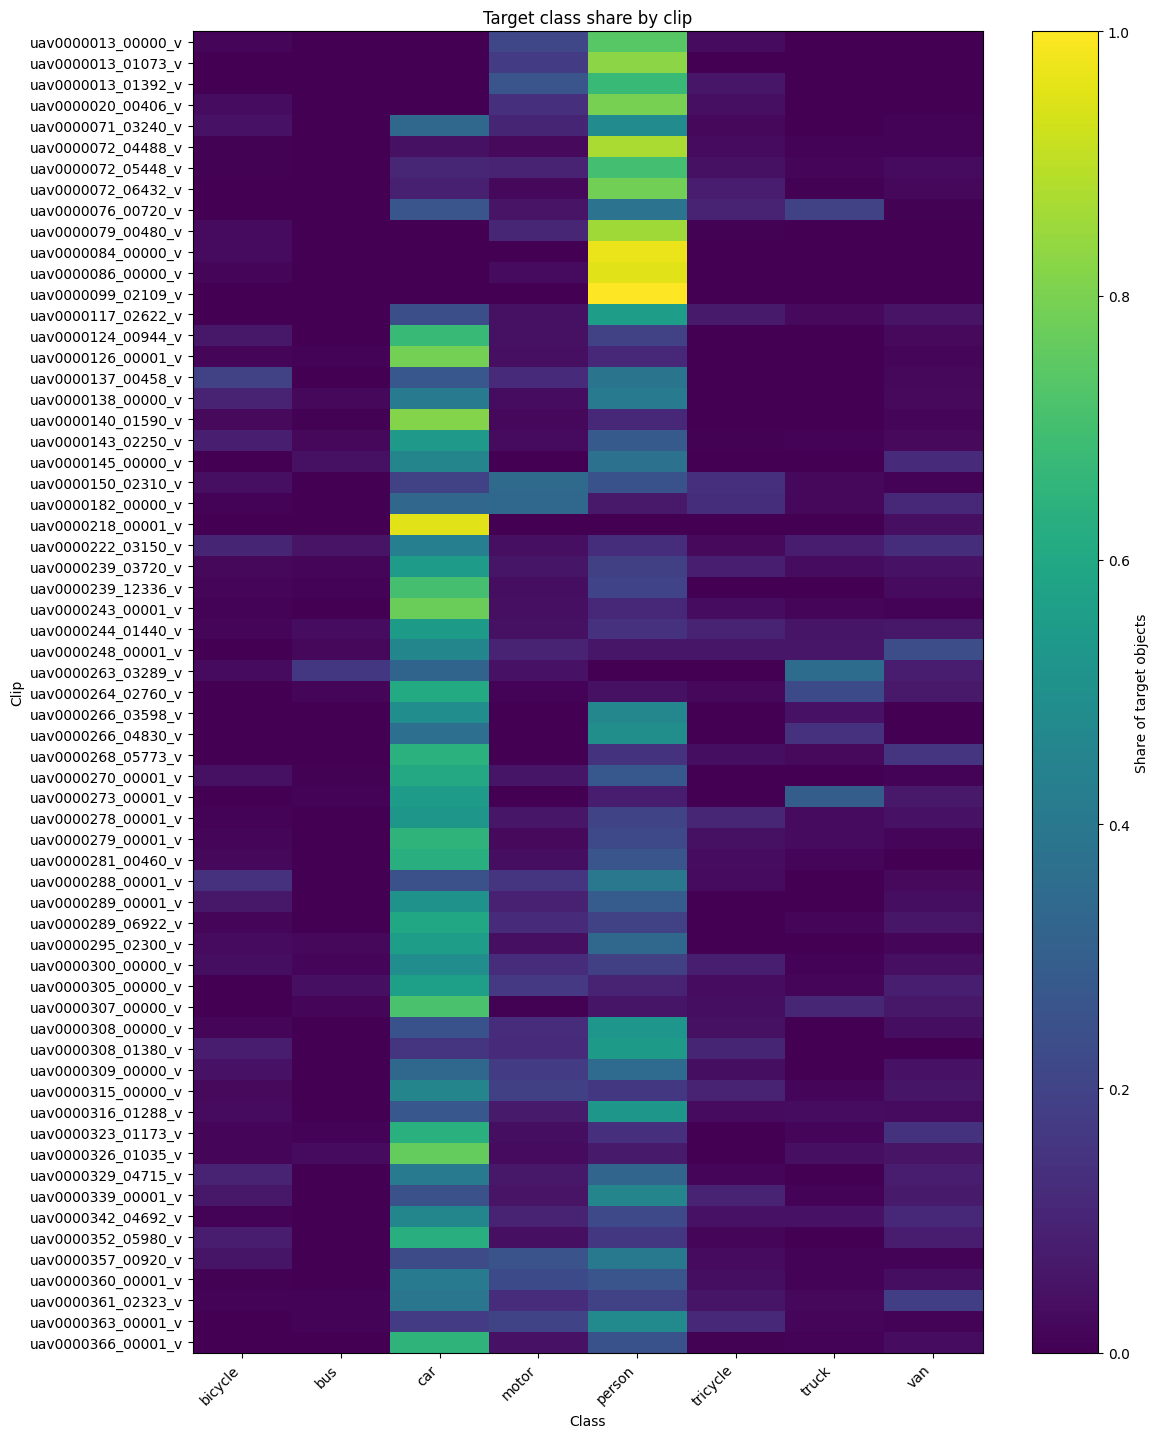

,orig_category_id,mapping_status,iscrowd,annotations
0,0,ignored region,1,66363
1,1,person,0,266709
2,2,person,0,112304
3,3,bicycle,0,46277
4,4,car,0,537122
5,5,van,0,53782
6,6,truck,0,31857
7,7,tricycle,0,32107
8,8,tricycle,0,14729
9,9,bus,0,9917


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

target_sized = du.add_box_dimensions(targets, target_only=False)
class_counts = (
    target_sized.groupby(["split", "class_name"]).size().rename("objects").reset_index()
)
display(class_counts.pivot(index="class_name", columns="split", values="objects").fillna(0).astype(int))
clip_counts = target_sized.groupby(["clip", "class_name"]).size().unstack(fill_value=0)
clip_shares = clip_counts.div(clip_counts.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, max(4, 0.23 * len(clip_shares))))
image = ax.imshow(clip_shares, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(title="Target class share by clip", xlabel="Class", ylabel="Clip")
ax.set_xticks(range(len(clip_shares.columns)), clip_shares.columns, rotation=45, ha="right")
ax.set_yticks(range(len(clip_shares.index)), clip_shares.index)
fig.colorbar(image, ax=ax, label="Share of target objects")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_share_by_clip.png", dpi=140)
plt.show()
def category_mapping_status(row):
    category_id = pd.to_numeric(row["category_id"], errors="coerce")
    crowd = pd.to_numeric(row["iscrowd"], errors="coerce")
    if pd.notna(crowd) and int(crowd) == 1:
        return "ignored region"
    if pd.notna(category_id) and 1 <= category_id <= len(du.CLASS_NAMES):
        return du.CLASS_NAMES[int(category_id) - 1]
    return "other / non-target"
annotations["mapping_status"] = annotations.apply(category_mapping_status, axis=1)
orig_breakdown = (
    annotations.groupby(["orig_category_id", "mapping_status", "iscrowd"], dropna=False)
    .size().rename("annotations").reset_index()
)
display(orig_breakdown.head(30))

**Observations:** TODO

# 4. Object sizes and input-resolution simulation
Summarize COCO size buckets, pixel dimensions, aspect ratios, per-clip object scale, and the number of pixels available at candidate letterbox sizes.

,class_name,size_bucket,count
0,all,small,297257
1,all,medium,781361
2,all,large,141030
3,bicycle,small,9998
4,bicycle,medium,34990
5,bicycle,large,1289
6,bus,small,400
7,bus,medium,3898
8,bus,large,5619
9,car,small,85464


box_w  box_h  sqrt_area  aspect_ratio
class_name                                           
bicycle    0.1   21.0   27.0      25.83          0.51
           0.5   47.0   45.0      43.86          0.93
           0.9   81.0   81.0      75.65          1.74
bus        0.1   35.0   36.0      41.83          0.62
           0.5  123.0  103.0     111.67          1.05
           0.9  342.4  216.0     264.68          2.90
car        0.1   29.0   24.0      28.39          0.82
           0.5   68.0   48.0      57.55          1.26
           0.9  156.0  108.0     121.75          2.44
motor      0.1   17.0   23.0      20.35          0.51
           0.5   37.0   43.0      39.80          0.80
           0.9   73.0   73.0      68.53          1.54
person     0.1   15.0   28.0      20.49          0.37
           0.5   26.0   51.0      36.66          0.50
           0.9   47.0   90.0      63.00          0.76
tricycle   0.1   24.0   25.0      24.98          0.66
           0.5   58.0   51.0      54.50          1.06
           0.9  123.0  103.0     104.38          1.82
truck      0.1   34.0   29.0      33.12          0.77
           0.5   81.0   69.0      73.94          1.08
           0.9  228.0  146.0     181.44          2.30
van        0.1   29.0   26.0      28.72          0.71
           0.5   57.0   47.0      51.28          1.13
           0.9  146.0  119.0     128.57          1.97

,clip,median_sqrt_area_px
0,uav0000239_12336_v,24.494897
1,uav0000248_00001_v,29.983329
2,uav0000264_02760_v,31.000000
3,uav0000278_00001_v,31.496031
4,uav0000182_00000_v,32.449961
5,uav0000239_03720_v,33.316662
6,uav0000279_00001_v,33.361655
7,uav0000243_00001_v,35.213634
8,uav0000099_02109_v,37.080992
9,uav0000270_00001_v,37.469988


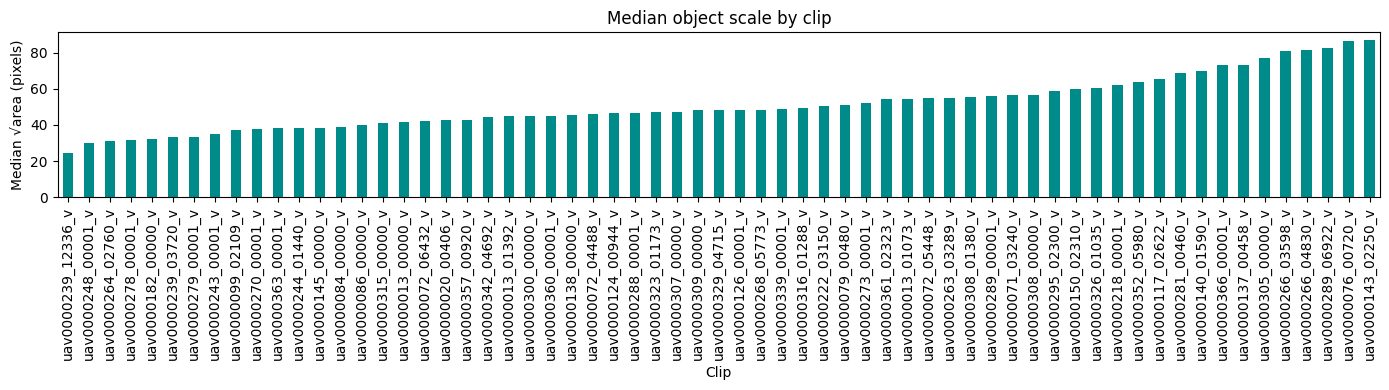

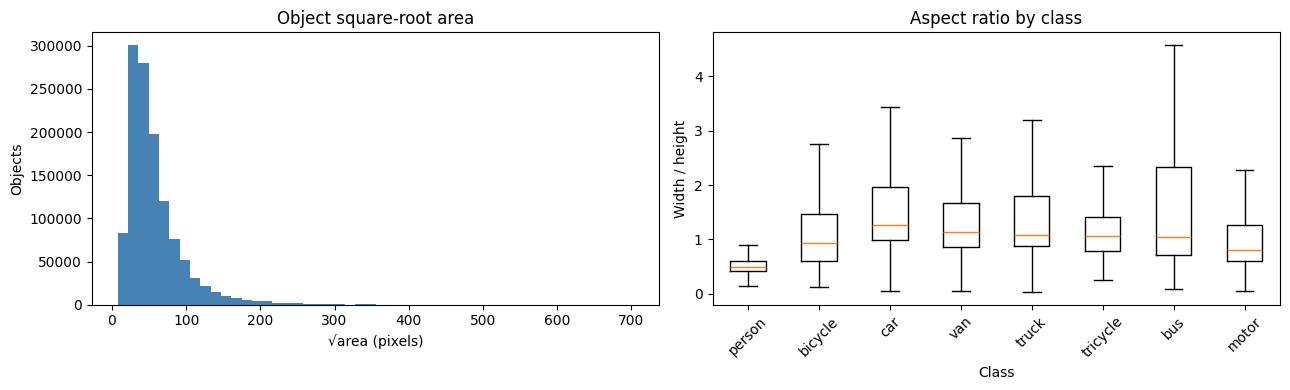

,imgsz,below_4px_pct,below_8px_pct,below_16px_pct,objects
0,640,1.73,21.75,69.17,1219648
1,960,0.67,5.93,40.25,1219648
2,1280,0.04,1.73,21.75,1219648
3,1536,0.01,0.99,12.80,1219648


In [18]:
size_summary = du.size_bucket_summary(targets)
display(size_summary.head(36))
display(target_sized.groupby("class_name")[["box_w", "box_h", "sqrt_area", "aspect_ratio"]].quantile([0.1, 0.5, 0.9]).round(2).head(30))
clip_size = target_sized.groupby("clip")["sqrt_area"].median().sort_values()
display(clip_size.rename("median_sqrt_area_px").reset_index().head(10))
ax = clip_size.plot(kind="bar", figsize=(14, 4), color="darkcyan")
ax.set(title="Median object scale by clip", xlabel="Clip", ylabel="Median √area (pixels)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "object_size_by_clip.png", dpi=140)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(target_sized["sqrt_area"], bins=50, color="steelblue")
axes[0].set(title="Object square-root area", xlabel="√area (pixels)", ylabel="Objects")
class_order = [name for name in du.CLASS_NAMES if name in target_sized["class_name"].unique()]
axes[1].boxplot(
    [target_sized.loc[target_sized["class_name"].eq(name), "aspect_ratio"].dropna() for name in class_order],
    tick_labels=class_order, showfliers=False
)
axes[1].set(title="Aspect ratio by class", xlabel="Class", ylabel="Width / height")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "object_size_distributions.png", dpi=140)
plt.show()
resolution_table = du.resized_small_side_shares(targets, images, IMGSZ_CANDIDATES)
display(resolution_table.round(2))

**Observations:** TODO

# 5. Anchor diagnostics
Run seeded IoU-distance k-means on width/height after letterboxing to `ANCHOR_IMGSZ`; anchor values are pixel dimensions at that size.

In [19]:
anchor_results = [
    du.kmeans_anchors(targets, images, ANCHOR_IMGSZ, k, seed=SEED)
    for k in ANCHOR_K_VALUES
]
du.save_json({"imgsz": ANCHOR_IMGSZ, "results": anchor_results}, ANCHORS_PATH)
display(pd.DataFrame([
    {"k": item["k"], "mean_best_iou": item["mean_best_iou"], "anchors_px": item["anchors"]}
    for item in anchor_results
]))
print(f"Saved anchors to {ANCHORS_PATH}")

,k,mean_best_iou,anchors_px
0,9,0.726761,"[[8.57, 12.1], [17.86, 14.62], [12.1, 23.19], ..."
1,12,0.757194,"[[7.06, 11.6], [13.11, 11.6], [10.08, 20.67], ..."


Saved anchors to /content/drone-multi-object-detection/results/anchors.json


**Observations:** TODO

# 6. Objects per frame and density
Inspect the frame-level target count tail against candidate `max_det=500` and DETR query counts of 300 and 500.

,frames,p99_objects_per_frame,max_objects_per_frame
0,27047,140.0,180


,clip,count,median,max
43,uav0000295_02300_v,346,79.5,180
21,uav0000150_02310_v,348,102.0,174
15,uav0000126_00001_v,412,130.0,166
17,uav0000138_00000_v,213,150.0,156
14,uav0000124_00944_v,398,129.0,134
38,uav0000279_00001_v,547,108.0,126
5,uav0000072_04488_v,85,108.0,124
16,uav0000137_00458_v,233,105.0,116
7,uav0000072_06432_v,97,85.0,113
58,uav0000357_00920_v,691,93.0,104


,capacity,frames_over_capacity,frames_at_or_over_capacity
0,300,0,0
1,500,0,0


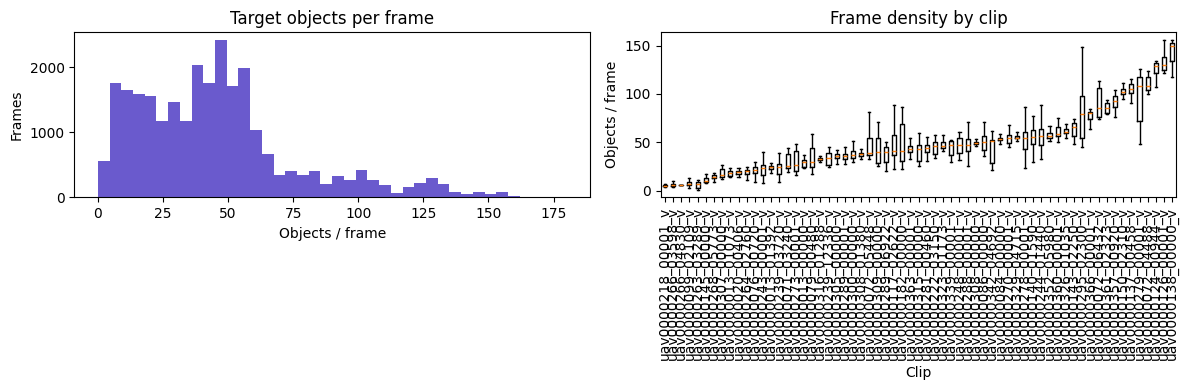

In [20]:
density, density_by_clip, density_stats = du.density_summary(images, targets)
display(pd.DataFrame([density_stats]))
display(density_by_clip.sort_values("max", ascending=False).head(12))
query_check = pd.DataFrame({
    "capacity": [300, 500],
    "frames_over_capacity": [int((density["objects"] > cap).sum()) for cap in [300, 500]],
    "frames_at_or_over_capacity": [int((density["objects"] >= cap).sum()) for cap in [300, 500]],
})
display(query_check)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(density["objects"], bins=40, color="slateblue")
axes[0].set(title="Target objects per frame", xlabel="Objects / frame", ylabel="Frames")
clip_order = density_by_clip.sort_values("median")["clip"]
axes[1].boxplot(
    [density.loc[density["clip"].eq(clip), "objects"] for clip in clip_order],
    tick_labels=clip_order, showfliers=False
)
axes[1].set(title="Frame density by clip", xlabel="Clip", ylabel="Objects / frame")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "objects_per_frame.png", dpi=140)
plt.show()

**Observations:** TODO

# 7. Ignored regions
Measure per-frame ignored-region incidence and covered area, and count target boxes with any positive-area intersection with an ignored region.

In [21]:
ignored_by_clip, ignored_stats = du.ignored_region_summary(images, targets, ignored)
display(ignored_stats)
display(ignored_by_clip.sort_values("frames_with_ignored", ascending=False).head(15))

,frames_with_ignored,frames,frames_with_ignored_pct,ignored_regions,mean_ignored_area_pct,target_boxes_intersecting_ignored,target_boxes
0,19524,27047,72.185455,67838,2.300197,42531,1219648


,clip,frames,frames_with_ignored,mean_ignored_area_pct
37,uav0000278_00001_v,962,962,5.018479
36,uav0000273_00001_v,872,735,0.290698
28,uav0000244_01440_v,721,721,1.845640
27,uav0000243_00001_v,768,663,1.915084
40,uav0000288_00001_v,1424,659,0.668156
58,uav0000357_00920_v,691,622,1.980593
31,uav0000264_02760_v,616,616,1.473804
44,uav0000300_00000_v,556,556,3.001657
32,uav0000266_03598_v,548,548,1.014657
38,uav0000279_00001_v,547,547,2.911441


**Observations:** TODO

# 8. Occlusion and truncation
Show annotation counts and normalized distributions for the source occlusion and truncation fields by target class.

occlusion


,class_name,occlusion,objects,class_share
0,bicycle,0.0,19286,0.416751
1,bicycle,1.0,25514,0.551332
2,bicycle,2.0,1477,0.031917
3,bus,0.0,5616,0.566300
4,bus,1.0,4099,0.413331
5,bus,2.0,202,0.020369
6,car,0.0,301966,0.562193
7,car,1.0,208883,0.388893
8,car,2.0,26273,0.048914
9,motor,0.0,59589,0.518869


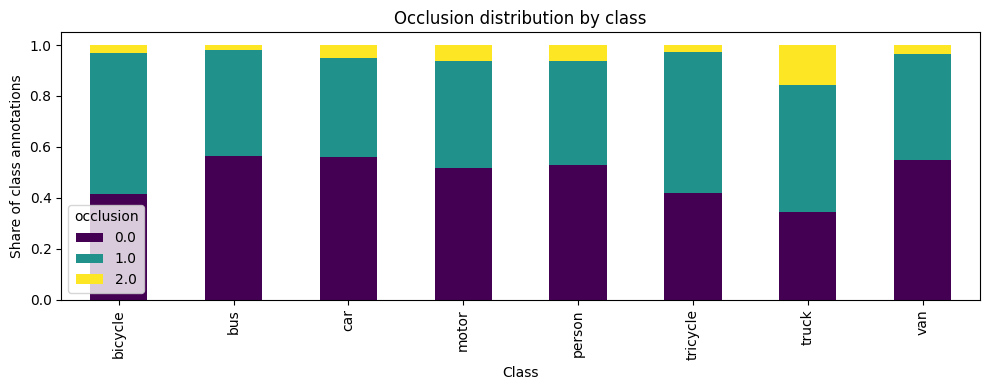

truncation


,class_name,truncation,objects,class_share
0,bicycle,0.0,45807,0.989844
1,bicycle,1.0,470,0.010156
2,bus,0.0,8559,0.863063
3,bus,1.0,1358,0.136937
4,car,0.0,506066,0.942181
5,car,1.0,31056,0.057819
6,motor,0.0,111109,0.967478
7,motor,1.0,3735,0.032522
8,person,0.0,370769,0.978249
9,person,1.0,8244,0.021751


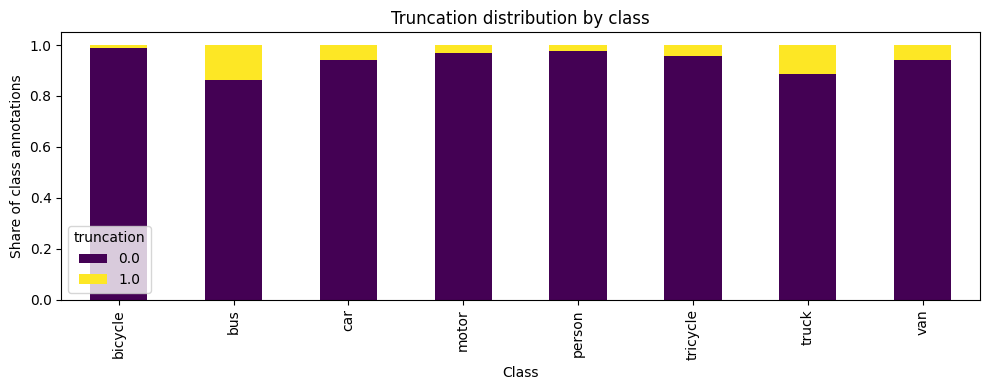

In [24]:
for field in ["occlusion", "truncation"]:
    distribution = (
        targets.groupby(["class_name", field], dropna=False).size()
        .rename("objects").reset_index()
    )
    distribution["class_share"] = distribution["objects"] / distribution.groupby("class_name")["objects"].transform("sum")
    print(field)
    display(distribution.head(32))
    pivot = distribution.pivot(index="class_name", columns=field, values="class_share").fillna(0)
    ax = pivot.plot(kind="bar", stacked=True, figsize=(10, 4), colormap="viridis")
    ax.set(title=f"{field.title()} distribution by class", xlabel="Class", ylabel="Share of class annotations")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{field}_by_class.png", dpi=140)
    plt.show()

**Observations:** TODO

# 9. Temporal redundancy and frame subsampling
Compare same-track IoU at frame lags and estimate the share of unique clip/track IDs never seen when retaining every kth frame.

,step,mean_track_iou,track_pairs,tracks_never_sampled_pct,tracks
0,1,0.851303,1097628,0.000000,7342
1,2,0.751677,1090077,0.408608,7342
2,3,0.675537,1082554,0.258785,7342
3,5,0.564680,1067598,0.735494,7342
4,10,0.408006,1031089,1.402887,7342
5,15,0.327638,995955,2.002179,7342
6,20,0.279554,961789,3.323345,7342
7,30,0.225396,896729,4.562789,7342


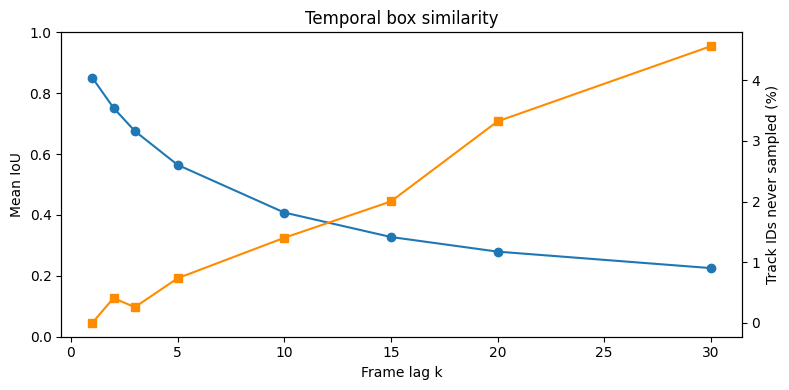

In [25]:
temporal = du.temporal_redundancy(train_images, train_targets, TEMPORAL_LAGS)
display(temporal)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(temporal["step"], temporal["mean_track_iou"], marker="o", label="Mean same-track IoU")
ax.set(title="Temporal box similarity", xlabel="Frame lag k", ylabel="Mean IoU", ylim=(0, 1))
ax2 = ax.twinx()
ax2.plot(temporal["step"], temporal["tracks_never_sampled_pct"], marker="s", color="darkorange", label="Tracks never sampled")
ax2.set_ylabel("Track IDs never sampled (%)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "temporal_redundancy.png", dpi=140)
plt.show()

**Observations:** TODO

# 10. Visual verification
Render six frames selected across clips, including sparse/dense scenes, smallest/largest resolutions, and ignored-region-heavy examples.

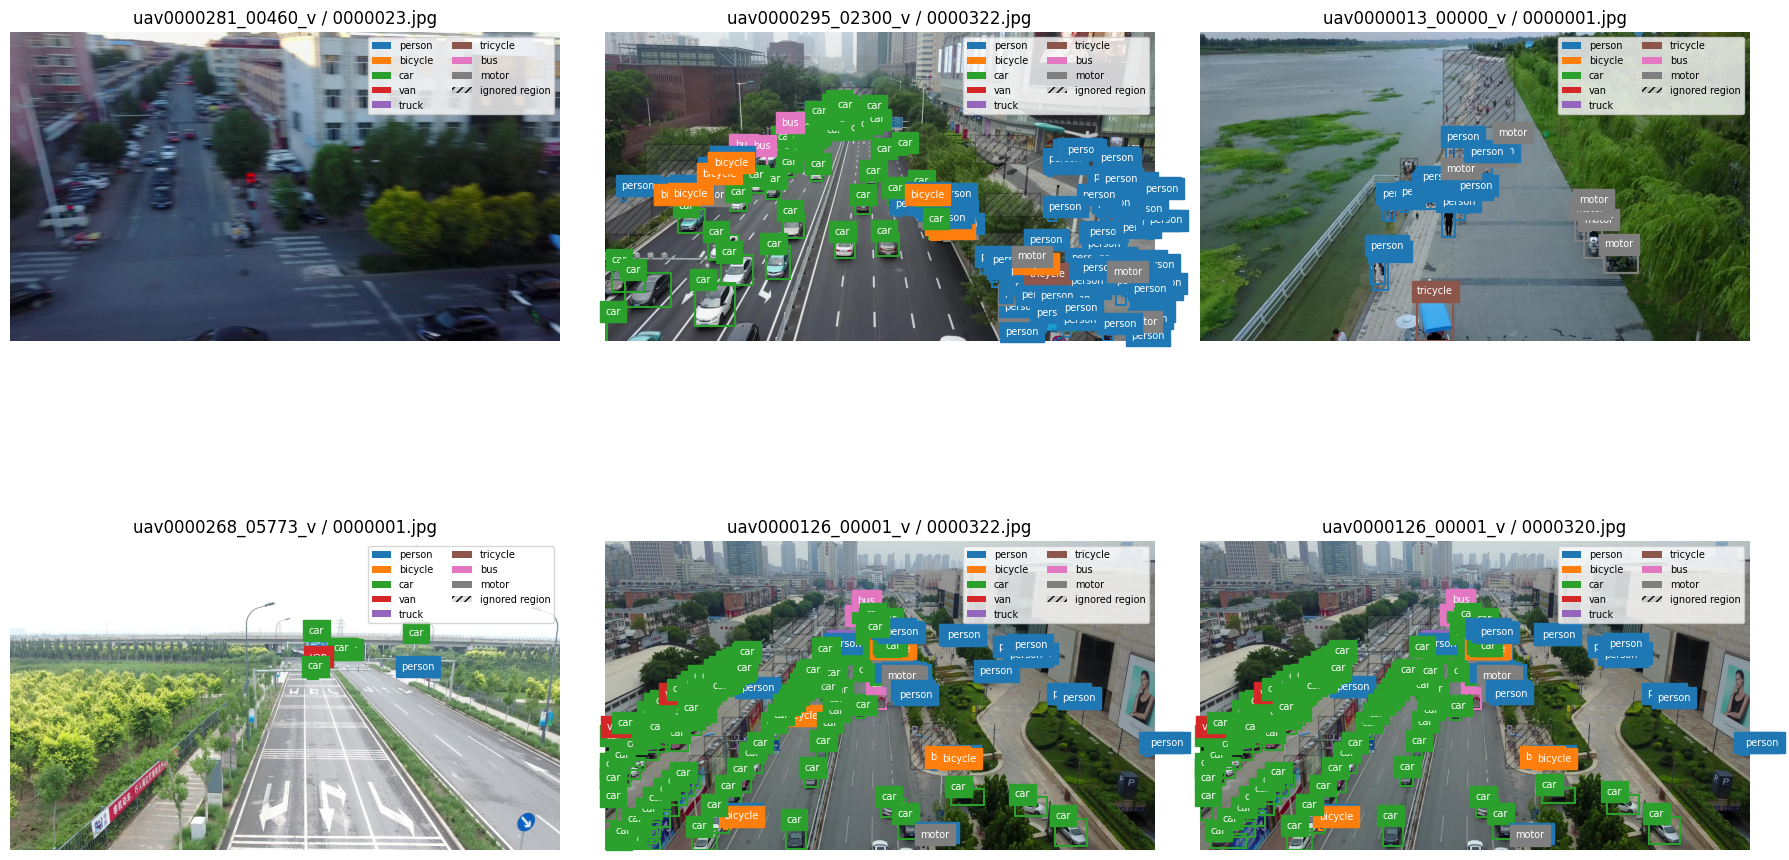

,split,clip,frame_id,width,height,objects,ignored
0,train,uav0000281_00460_v,23,1904,1071,0.0,0.0
1,train,uav0000295_02300_v,322,2720,1530,180.0,9.0
2,train,uav0000013_00000_v,1,1344,756,23.0,4.0
3,val,uav0000268_05773_v,1,3840,2160,8.0,0.0
4,train,uav0000126_00001_v,322,2688,1512,166.0,22.0
5,train,uav0000126_00001_v,320,2688,1512,156.0,21.0


In [26]:
examples = du.select_visual_examples(images, targets, ignored, VISUAL_FRAME_COUNT)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (_, frame) in zip(axes.flat, examples.iterrows()):
    frame_targets = targets.loc[targets["image_id"].eq(frame["id"])]
    frame_ignored = ignored.loc[ignored["image_id"].eq(frame["id"])]
    frame_path = du.image_path_for(DATA_ROOT / str(frame["split"]), frame["file_name"])
    du.visualize_frame(frame_path, frame_targets, frame_ignored, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ground_truth_examples.png", dpi=150, bbox_inches="tight")
plt.show()
display(examples[["split", "clip", "frame_id", "width", "height", "objects", "ignored"]])

**Observations:** TODO

# 11. Sequence-level splits and sampled frame lists
Check train/validation clip separation, summarize five seeded grouped folds over train clips, and save the selected every-kth-frame lists.

In [27]:
train_clips = set(train_images["clip"].astype(str))
val_clips = set(val_images["clip"].astype(str))
clip_overlap = sorted(train_clips & val_clips)
assert not clip_overlap, f"Train/val clips overlap: {clip_overlap}"
print(f"Train clips: {len(train_clips)} | val clips: {len(val_clips)} | overlap: {len(clip_overlap)}")
folds = du.make_group_folds(train_images, train_targets, FOLD_COUNT, SEED)
du.save_json({"seed": SEED, "n_splits": FOLD_COUNT, "folds": folds}, SPLITS_DIR / "folds.json")
display(pd.DataFrame([
    {"fold": fold["fold"], "val_clips": len(fold["val_clips"]), "train_frames": fold["train_frames"],
     "val_frames": fold["val_frames"], "train_class_counts": fold["train_class_counts"],
     "val_class_counts": fold["val_class_counts"],
     "train_median_sqrt_area": fold["train_median_sqrt_area"],
     "val_median_sqrt_area": fold["val_median_sqrt_area"]}
    for fold in folds
]))
sampled_frames = {
    split: du.subsampled_frame_list(images.loc[images["split"].eq(split)], SUBSAMPLE_STEP)
    for split in ["train", "val"]
}
du.save_json({"step": SUBSAMPLE_STEP, "frames": sampled_frames}, SPLITS_DIR / "subsampled_frames.json")
print({split: len(items) for split, items in sampled_frames.items()})

Train clips: 56 | val clips: 7 | overlap: 0


,fold,val_clips,train_frames,val_frames,train_class_counts,val_class_counts,train_median_sqrt_area,val_median_sqrt_area
0,0,12,19249,4952,"{'0': 258917, '1': 32122, '2': 360076, '3': 40...","{'0': 69784, '1': 8133, '2': 145225, '3': 6878...",46.432747,44.090815
1,1,11,19885,4316,"{'0': 281520, '1': 36848, '2': 412895, '3': 39...","{'0': 47181, '1': 3407, '2': 92406, '3': 7551,...",44.899889,50.418251
2,2,11,18144,6057,"{'0': 272388, '1': 35599, '2': 388581, '3': 25...","{'0': 56313, '1': 4656, '2': 116720, '3': 2100...",46.989360,40.987803
3,3,11,19327,4874,"{'0': 280438, '1': 28706, '2': 439595, '3': 41...","{'0': 48263, '1': 11549, '2': 65706, '3': 5387...",45.923850,44.788391
4,4,11,20199,4002,"{'0': 221541, '1': 27745, '2': 420057, '3': 40...","{'0': 107160, '1': 12510, '2': 85244, '3': 612...",44.788391,49.040799


{'train': 4868, 'val': 571}


**Observations:** TODO

# 12. Summary
Persist compact dataset statistics and analysis parameters for later model notebooks.

In [28]:
summary = {
    "seed": SEED,
    "splits": overview.to_dict("records"),
    "class_counts": class_counts.to_dict("records"),
    "resolution_simulation": resolution_table.to_dict("records"),
    "anchors": {"imgsz": ANCHOR_IMGSZ, "results": anchor_results},
    "density": density_stats,
    "ignored_regions": ignored_stats.to_dict("records"),
    "temporal_redundancy": temporal.to_dict("records"),
    "subsample_step": SUBSAMPLE_STEP,
    "sampled_frame_counts": {split: len(items) for split, items in sampled_frames.items()},
    "train_val_clip_overlap": clip_overlap,
}
du.save_json(summary, RESULTS_DIR / "eda_summary.json")
print(f"Saved summary to {RESULTS_DIR / 'eda_summary.json'}")

Saved summary to /content/drone-multi-object-detection/results/eda/eda_summary.json


**Observations:** TODO